# Ferdeer Case Demo: Who Are Ferdeer Retail's Most Valuable Customers?

## Part A. Cleaning and Analysing Data

### 1. Introduction

**Research Question:** Who are Ferdeer Retail's most valuable customers, and how do they differ from the other customers in how much they spend, how long they stay on the site and how often their visits end in a purchase?

**Method:** This is a **descriptive analysis**. We summarise three years of customer, sales, campaign and browsing data to describe *what happened*. We first set the scene with a short overview of sales revenue by year, product category and country. We then identify the valuable customers with a rule-based segmentation (RFM) and with a data-driven segmentation (K-means clustering) on customers' spending and session duration, and we compare the clusters on their conversion rate. We do not claim that any pattern is *caused* by marketing or by customer behaviour — campaigns and customer behaviour were not randomly assigned — and we do not build a model to *predict* future purchases.

### 2. Data Preparation & Analysis

#### (1) Load Libraries

At the beginning of this project, we import the necessary libraries.

In [1]:
library(tidyverse)   # data wrangling and visualisation
library(janitor)     # clean_names(): tidy column names
library(scales)      # formatting axis labels (e.g., percent, dollar)
library(patchwork)   # combining multiple plots
library(ggokabeito)  # colour-blind-friendly palette (course default)
library(recipes)     # scaling variables before clustering
library(cluster)     # K-means
library(factoextra)  # choosing k and visualising clusters
library(broom)       # augment(): attach cluster labels back to the data
library(vtable)      # st(): summary statistics table

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.0     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.2     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.1     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors



Attaching package: ‘janitor’




The following objects are masked from ‘package:stats’:

    chisq.test, fisher.test





Attaching package: ‘scales’




...

Welcome to factoextra!



Want to learn more? See two factoextra-related books at https://www.datanovia.com/en/product/practical-guide-to-principal-component-methods-in-r/



Loading required package: kableExtra




Attaching package: ‘kableExtra’




The following object is masked from ‘package:dplyr’:

    group_rows




#### (2) Data Loading

**(a) Load Raw Datasets**

Then, we load each of the eight files into R as a tibble. Here we use `clean_names()` to convert the column names into lower-case snake_case.

In [2]:
data_load <- function(dir) {
    df_raw <- read_csv(dir) |> clean_names()
    return(df_raw)
}

In [3]:
df_raw_customer_demographics <- data_load("../data/customer_demographics.csv")
df_raw_customer_profile      <- data_load("../data/customer_profile.csv")
df_raw_products              <- data_load("../data/products.csv")
df_raw_category_lookup       <- data_load("../data/category_lookup.csv")
df_raw_campaigns             <- data_load("../data/campaigns.csv")
df_raw_campaign_spend_wide   <- data_load("../data/campaign_spend_wide.csv")
df_raw_events                <- data_load("../data/events.csv")
df_raw_transactions          <- data_load("../data/transactions.csv")

Rows: 10000 Columns: 5


── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (2): cntry, Gender
dbl  (2): CustomerID, Age
date (1): Signup Date



ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Rows: 10100 Columns: 4


── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): LoyaltyTier, acquisition channel, ExperimentGroup
dbl (1): cust_id


...

── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (5): Event Type, device, Traffic Source, PageCategory, ExperimentGroup
dbl  (6): EventID, cust_id, SessionID, prod_id, campaign_id, session duratio...
dttm (1): TimeStamp



ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Rows: 17800 Columns: 9


── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (1): Refunded
dbl  (7): TxnID, cust_id, prod_id, Qty, discount %, Revenue (USD), campaign_id
dttm (1): TimeStamp



ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


The two customer files describe details of the customers, so we can combine them into a single customer table using `left_join()`. Same approach is applied to the product and campaign files. The events and transactions tables stay as they are.

In [4]:
# Customers: customer_demographics + customer_profile
df_customers <-
    df_raw_customer_demographics |>
    rename(cust_id = customer_id) |>
    left_join(df_raw_customer_profile, by = join_by(cust_id))

# Products: products + categories
df_products <-
    df_raw_products |>
    left_join(df_raw_category_lookup, by = join_by(cat_code))

# Campaigns: campaign + spend
df_campaigns <-
    df_raw_campaigns |>
    left_join(df_raw_campaign_spend_wide, by = join_by(campaign_id))

df_events <- df_raw_events

df_transactions <- df_raw_transactions

The following is a preview of the five raw tables.

In [5]:
tibble(
    table  = c("df_customers", "df_products", "df_campaigns", "df_events", "df_transactions"),
    n_rows = c(nrow(df_customers), nrow(df_products), nrow(df_campaigns), nrow(df_events), nrow(df_transactions)),
    n_cols = c(ncol(df_customers), ncol(df_products), ncol(df_campaigns), ncol(df_events), ncol(df_transactions))
)

table,n_rows,n_cols
<chr>,<int>,<int>
df_customers,10100,8
df_products,2000,7
df_campaigns,50,10
df_events,199627,12
df_transactions,17800,9


In [6]:
df_customers |> slice_head(n = 5)

cust_id,signup_date,cntry,age,gender,loyalty_tier,acquisition_channel,experiment_group
<dbl>,<date>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>
61413,2022-10-19,BR,41,Male,Bronze,Email,Control
54425,2023-12-08,IN,27,Male,Silver,Email,Control
99556,2023-05-15,US,43,Male,Bronze,Referral,Variant_B
74362,2022-03-15,US,31,Female,Bronze,Paid Search,Control
47128,2021-04-18,IN,25,Male,Bronze,Organic,Control


In [7]:
df_products |> slice_head(n = 5)

prod_id,cat_code,brand,base_price,launch_date,is_premium,category_name
<dbl>,<chr>,<chr>,<dbl>,<date>,<dbl>,<chr>
1,C04,Brand_58,14.19,2021-08-02,0,Grocery
2,C03,Brand_1,25.80,2021-09-14,0,Fashion
3,C02,Brand_70,165.46,2021-01-18,1,Electronics
4,C03,Brand_56,75.45,2023-03-03,1,Fashion
5,C06,Brand_1,72.50,2022-04-19,1,Sports


In [8]:
df_campaigns |> slice_head(n = 5)

campaign_id,channel,objective,start_date,end_date,target_segment,expected_uplift,spend_2021,spend_2022,spend_2023
<dbl>,<chr>,<chr>,<date>,<date>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,Paid Search,Cross-sell,2021-10-25,2021-11-26,Deal Seekers,0.022,5476,28884,52396
2,Email,Retention,2021-10-24,2021-12-24,Deal Seekers,0.116,49538,30047,59294
3,Email,Reactivation,2023-10-08,2023-11-30,Churn Risk,0.100,NA,NA,43200
4,Display,Reactivation,2022-07-25,2022-10-07,Deal Seekers,0.111,NA,31095,36248
5,Social,Acquisition,2022-07-09,2022-09-29,New Customers,0.144,NA,48683,31072


In [9]:
df_events |> slice_head(n = 5)

event_id,time_stamp,cust_id,session_id,event_type,prod_id,device,traffic_source,campaign_id,page_category,session_duration_sec,experiment_group
<dbl>,<dttm>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<chr>
2,2021-12-03 21:36:50,71340,96426,purchase,986,desktop,Email,10,PDP,32.4,Control
40,2021-03-27 09:54:18,95397,586416,bounce,NA,mobile,Organic,0,Home,51.5,Control
46,2021-05-07 18:33:02,6337,378695,add_to_cart,1683,desktop,Email,12,Cart,40.8,Variant_A
47,2023-12-05 14:08:55,91993,45133,view,157,mobile,Paid Search,14,PDP,235.3,Control
49,2022-09-26 21:14:27,48406,657292,view,836,mobile,Paid Search,18,PDP,68.8,Control


In [10]:
df_transactions |> slice_head(n = 5)

txn_id,time_stamp,cust_id,prod_id,qty,discount_percent,revenue_usd,campaign_id,refunded
<dbl>,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
13,2023-03-09 15:36:33,45997,1513,1,0.0,100.76,43,No
39,2021-01-18 20:52:06,29955,1543,1,0.1,39.83,0,No
50,2021-11-11 20:27:59,38085,558,1,0.0,146.29,18,No
53,2021-01-25 13:56:45,92155,841,1,0.0,44.12,7,No
69,2022-04-30 17:33:31,66995,1691,2,0.0,147.30,13,No


**(b) Summary Statistics of the Raw Data**

Before cleaning, we look at the summary of the five tables with the `st()` function from the `vtable` package, which reports summary statistics for numeric columns and category counts for text and factor columns. This step helps us identify data anomalies before proceeding with data cleaning.

In [11]:
df_customers |>
    select(-cust_id) |>
    mutate(cntry = as.factor(cntry)) |>
    st(out = "kable")



Table: Summary Statistics

|Variable            |N     |Mean |Std. Dev. |Min |Pctl. 25 |Pctl. 75 |Max |
|:-------------------|:-----|:----|:---------|:---|:--------|:--------|:---|
|cntry               |10100 |     |          |    |         |         |    |
|... au              |58    |1%   |          |    |         |         |    |
|... AU              |622   |6%   |          |    |         |         |    |
|... br              |81    |1%   |          |    |         |         |    |
|... BR              |940   |9%   |          |    |         |         |    |
|... ca              |78    |1%   |          |    |         |         |    |
|... CA              |891   |9%   |          |    |         |         |    |
|... de              |66    |1%   |          |    |         |         |    |
|... DE              |732   |7%   |          |    |         |         |    |
|... in              |169   |2%   |          |    |         |         |    |
|... IN              |1872  |19%  |          | 

In [12]:
df_products |>
    select(-prod_id) |>
    st(out = "kable")



Table: Summary Statistics

|Variable        |N    |Mean |Std. Dev. |Min |Pctl. 25 |Pctl. 75 |Max |
|:---------------|:----|:----|:---------|:---|:--------|:--------|:---|
|cat_code        |2000 |     |          |    |         |         |    |
|... C01         |201  |10%  |          |    |         |         |    |
|... C02         |455  |23%  |          |    |         |         |    |
|... C03         |418  |21%  |          |    |         |         |    |
|... C04         |312  |16%  |          |    |         |         |    |
|... C05         |396  |20%  |          |    |         |         |    |
|... C06         |218  |11%  |          |    |         |         |    |
|base_price      |1985 |71   |54        |-99 |32       |98       |465 |
|is_premium      |2000 |0.5  |0.5       |0   |0        |1        |1   |
|category_name   |2000 |     |          |    |         |         |    |
|... Beauty      |201  |10%  |          |    |         |         |    |
|... Electronics |455  |23%  |     

In [13]:
df_campaigns |>
    select(-campaign_id) |>
    st(out = "kable")



Table: Summary Statistics

|Variable          |N  |Mean  |Std. Dev. |Min   |Pctl. 25 |Pctl. 75 |Max   |
|:-----------------|:--|:-----|:---------|:-----|:--------|:--------|:-----|
|channel           |50 |      |          |      |         |         |      |
|... Affiliate     |11 |22%   |          |      |         |         |      |
|... Display       |9  |18%   |          |      |         |         |      |
|... Email         |11 |22%   |          |      |         |         |      |
|... Paid Search   |11 |22%   |          |      |         |         |      |
|... Social        |8  |16%   |          |      |         |         |      |
|objective         |50 |      |          |      |         |         |      |
|... Acquisition   |10 |20%   |          |      |         |         |      |
|... Cross-sell    |12 |24%   |          |      |         |         |      |
|... Reactivation  |15 |30%   |          |      |         |         |      |
|... Retention     |13 |26%   |          |     

In [14]:
df_events |>
    select(-event_id, -cust_id, -session_id, -prod_id, -campaign_id) |>
    mutate(traffic_source = as.factor(traffic_source)) |>
    st(out = "kable")



Table: Summary Statistics

|Variable             |N      |Mean |Std. Dev. |Min |Pctl. 25 |Pctl. 75 |Max    |
|:--------------------|:------|:----|:---------|:---|:--------|:--------|:------|
|event_type           |199627 |     |          |    |         |         |       |
|... add_to_cart      |27081  |14%  |          |    |         |         |       |
|... bounce           |18966  |10%  |          |    |         |         |       |
|... click            |36103  |18%  |          |    |         |         |       |
|... purchase         |17650  |9%   |          |    |         |         |       |
|... view             |99827  |50%  |          |    |         |         |       |
|device               |195600 |     |          |    |         |         |       |
|... desktop          |68379  |35%  |          |    |         |         |       |
|... mobile           |117555 |60%  |          |    |         |         |       |
|... tablet           |9666   |5%   |          |    |         |      

In [15]:
df_transactions |>
    select(-txn_id, -cust_id, -prod_id, -campaign_id) |>
    st(out = "kable")



Table: Summary Statistics

|Variable         |N     |Mean  |Std. Dev. |Min  |Pctl. 25 |Pctl. 75 |Max  |
|:----------------|:-----|:-----|:---------|:----|:--------|:--------|:----|
|qty              |17800 |1.6   |0.85      |-2   |1        |2        |4    |
|discount_percent |17800 |0.024 |0.05      |0    |0        |0        |0.2  |
|revenue_usd      |16713 |115   |117       |-753 |42       |152      |1394 |
|refunded         |17800 |      |          |     |         |         |     |
|... No           |17488 |98%   |          |     |         |         |     |
|... Yes          |312   |2%    |          |     |         |         |     |

#### (3) Data Cleaning

**(a) Prepare the Clean Datasets**

The summary statistics above show what is wrong with the data. We now clean the five tables one by one. For all five tables, some common cleaning steps are applied, e.g., dropping exact duplicate rows, retaining only the necessary columns, and deleting rows with missing values.

**Customers:** The summary statistics for the customer table indicate that the `cntry` column contains country codes in both upper and lower case. We need to convert country codes to upper case.

In [16]:
df_customers_clean <-
    df_customers |>
    distinct() |>                            # 1. drop exact duplicate rows
    select(cust_id, cntry) |>                # keep only the columns we need
    mutate(cntry = str_to_upper(cntry)) |>   # 2. convert country codes to upper case (us -> US)
    drop_na()                                # 3. delete rows with missing values

**Products:** The columns we used in products table are `prod_id` and `category`. So, an anomaly in the `price` column does not affect our analysis, and we do not need to clean it. We only keep the product identifier and the category name.

In [17]:
df_products_clean <-
    df_products |>
    distinct() |>                       # 1. drop exact duplicate rows
    select(prod_id, category_name) |>   # keep only the columns we need
    drop_na()                           # delete rows with missing values

**Transactions:** In the transactions table, we remove transactions with zero or negative quantities, as a purchase involves at least one unit. In this step, we also need to convert purchase dates to date format.

In [18]:
df_transactions_clean <-
    df_transactions |>
    distinct() |>                                                       # 1. drop exact duplicate rows
    filter(qty >= 1) |>                                                 # 2. delete impossible quantities
    mutate(purchase_date = as_date(time_stamp)) |>
    select(cust_id, prod_id, purchase_date, revenue_usd, refunded) |>   # keep only the columns we need
    drop_na()                                                           # 3. delete rows with missing values (revenue and product)

**Events:** The event table describes customer interactions on the platform. The summary statistics indicate that some events have impossible session durations (e.g., −1 or extremely high values like 999,999 seconds). We need to remove these rows. We additionally create an indicator variable, `purchased`, which equals 1 if the event type is a purchase.

In [19]:
df_events_clean <-
    df_events |>
    mutate(purchased = if_else(event_type == "purchase", 1, 0)) |>   # did the visit end in a purchase?
    select(cust_id, session_duration_sec, purchased) |>              # keep only the columns we need
    filter(
        session_duration_sec >= 0,
        session_duration_sec <= 3600
    ) |>                                                             # 1. delete impossible durations
    drop_na()                                                        # 2. delete rows with missing values

**Campaigns:** Campaign spend is stored in a wide layout, with one column per year. We reshape it into a tidy long table (one row per campaign and year) with `pivot_longer()`, which also deletes the missing years. We keep the campaign identifier, the year and the spend.

In [20]:
df_campaigns_clean <-
    df_campaigns |>
    distinct() |> 
    select(campaign_id, starts_with("spend_")) |>
    pivot_longer(
        cols           = starts_with("spend_"),
        names_to       = c(".value", "year"),
        names_sep      = "_",
        values_drop_na = TRUE 
    ) |>
    mutate(year = as.numeric(year)) |>
    drop_na()

**(b) Summary of Clean Tables**

After the data cleaning process, we present the summary of the clean tables, including the number of rows and columns for each table.

In [21]:
tibble(
    table      = c("df_customers_clean", "df_products_clean", "df_transactions_clean", "df_events_clean", "df_campaigns_clean"),
    raw_rows   = c(nrow(df_customers), nrow(df_products), nrow(df_transactions), nrow(df_events), nrow(df_campaigns)),
    clean_rows = c(nrow(df_customers_clean), nrow(df_products_clean), nrow(df_transactions_clean), nrow(df_events_clean), nrow(df_campaigns_clean)),
    clean_cols = c(ncol(df_customers_clean), ncol(df_products_clean), ncol(df_transactions_clean), ncol(df_events_clean), ncol(df_campaigns_clean))
)

table,raw_rows,clean_rows,clean_cols
<chr>,<int>,<int>,<int>
df_customers_clean,10100,10000,2
df_products_clean,2000,2000,2
df_transactions_clean,17800,16518,5
df_events_clean,199627,198094,3
df_campaigns_clean,50,100,3


In [22]:
df_customers_clean |>
    select(-cust_id) |>
    mutate(cntry = as.factor(cntry)) |>
    st(out = "kable")



Table: Summary Statistics

|Variable |N     |Percent |
|:--------|:-----|:-------|
|cntry    |10000 |        |
|... AU   |668   |7%      |
|... BR   |1010  |10%     |
|... CA   |958   |10%     |
|... DE   |789   |8%      |
|... IN   |2024  |20%     |
|... UK   |1042  |10%     |
|... US   |3509  |35%     |

In [23]:
df_products_clean |>
    select(-prod_id) |>
    st(out = "kable")



Table: Summary Statistics

|Variable        |N    |Percent |
|:---------------|:----|:-------|
|category_name   |2000 |        |
|... Beauty      |201  |10%     |
|... Electronics |455  |23%     |
|... Fashion     |418  |21%     |
|... Grocery     |312  |16%     |
|... Home        |396  |20%     |
|... Sports      |218  |11%     |

In [24]:
df_transactions_clean |>
    select(-cust_id, -prod_id) |>
    st(out = "kable")



Table: Summary Statistics

|Variable    |N     |Mean |Std. Dev. |Min  |Pctl. 25 |Pctl. 75 |Max  |
|:-----------|:-----|:----|:---------|:----|:--------|:--------|:----|
|revenue_usd |16518 |115  |117       |-753 |42       |152      |1394 |
|refunded    |16518 |     |          |     |         |         |     |
|... No      |16236 |98%  |          |     |         |         |     |
|... Yes     |282   |2%   |          |     |         |         |     |

In [25]:
df_events_clean |>
    select(-cust_id) |>
    st(out = "kable")



Table: Summary Statistics

|Variable             |N      |Mean  |Std. Dev. |Min |Pctl. 25 |Pctl. 75 |Max  |
|:--------------------|:------|:-----|:---------|:---|:--------|:--------|:----|
|session_duration_sec |198094 |130   |147       |0.1 |58       |164      |3597 |
|purchased            |198094 |0.088 |0.28      |0   |0        |0        |1    |

In [26]:
df_campaigns_clean |>
    select(-campaign_id) |>
    mutate(year = as.factor(year)) |>
    st(out = "kable")



Table: Summary Statistics

|Variable |N   |Mean  |Std. Dev. |Min  |Pctl. 25 |Pctl. 75 |Max   |
|:--------|:---|:-----|:---------|:----|:--------|:--------|:-----|
|year     |100 |      |          |     |         |         |      |
|... 2021 |16  |16%   |          |     |         |         |      |
|... 2022 |34  |34%   |          |     |         |         |      |
|... 2023 |50  |50%   |          |     |         |         |      |
|spend    |100 |31637 |15823     |5476 |17232    |45158    |59294 |

After data cleaning, we can see that all the fields retained for analysis are free from data anomalies, for example abnormal values or inconsistent formatting.

#### (4) Data Processing

In this step, we build the customer-level variables used in the analysis, in two groups: how customers **purchase**, from the transaction table, and how customers **browse**, from the event table. In the end, we join both groups to the clean customer table, so that all later customer analyses use one table.

**(a) Customer Purchasing Behavior**

In this part, we prepare the necessary customer-level purchasing variables for RFM analysis. We start with the purchasing records. The basis is the **completed purchases**: the non-refunded transactions, with the product category attached from the clean product table. Excluding refunds means that we count only sales that the customer kept.

In [27]:
df_purchases <-
    df_transactions_clean |>
    filter(refunded == "No") |>                           # keep only completed (non-refunded) sales
    left_join(df_products_clean, by = join_by(prod_id))   # attach the product category

df_purchases |> slice_head(n = 5)

cust_id,prod_id,purchase_date,revenue_usd,refunded,category_name
<dbl>,<dbl>,<date>,<dbl>,<chr>,<chr>
45997,1513,2023-03-09,100.76,No,Sports
29955,1543,2021-01-18,39.83,No,Fashion
38085,558,2021-11-11,146.29,No,Electronics
92155,841,2021-01-25,44.12,No,Fashion
66995,1691,2022-04-30,147.30,No,Home


Following the RFM approach, we describe the purchasing behaviour of each buyer by three measures computed from the completed purchases:

- **Recency:** whole months between the customer's last purchase and the analysis date, 1 January 2024 (the day after the data end);
- **Frequency:** the number of completed purchases;
- **Monetary:** the total amount spent, in USD.

In [28]:
date_analysis <- as_date("2024-01-01")

df_customer_purchasing <-
    df_purchases |>
    group_by(cust_id) |>
    summarise(
        last_purch_date = max(purchase_date), # date of the most recent purchase
        frequency       = n(),                # total number of purchases for the customer
        monetary        = sum(revenue_usd)    # total revenue generated by the customer
    ) |>
    ungroup() |>
    mutate(
        # number of months since the last purchase
        recency = interval(last_purch_date, date_analysis) %/% months(1)
    ) |>
    select(cust_id, recency, frequency, monetary)

df_customer_purchasing |> slice_head(n = 5)

cust_id,recency,frequency,monetary
<dbl>,<dbl>,<int>,<dbl>
1,11,1,88.80
26,20,1,54.35
27,8,1,81.30
32,23,1,100.17
49,34,1,39.19


**(b) Customer Browsing Behavior**

Next, we describe the browsing behaviour of each customer from the clean event table. For each customer we compute the number of visits, the average session duration and the conversion rate, which is the share of visits that ended in a purchase.

In [29]:
# Browsing behaviour of each customer
df_customer_browsing <-
    df_events_clean |>
    group_by(cust_id) |>
    summarise(
        n_visits     = n(),
        avg_duration = mean(session_duration_sec),
        conversion   = mean(purchased)
    ) |>
    ungroup()

df_customer_browsing |> slice_head(n = 5)

cust_id,n_visits,avg_duration,conversion
<dbl>,<int>,<dbl>,<dbl>
1,18,189.1000,0.05555556
6,23,119.3609,0.00000000
16,14,107.9214,0.00000000
26,21,101.7238,0.04761905
27,19,119.0158,0.05263158


**(c) Customer Full Table**

Finally, we join the purchasing measures and the browsing measures to the clean customer table, so that every customer has one row. Customers who registered but never completed a purchase keep missing values for the purchasing measures and are labelled `"No purchase"`. Then, we can display some basic summary statistics for the full customer table.

In [30]:
df_customer_full_clean <-
    df_customers_clean |>
    left_join(df_customer_purchasing, by = join_by(cust_id)) |>
    left_join(df_customer_browsing, by = join_by(cust_id)) |>
    mutate(buyer = if_else(is.na(frequency), "No purchase", "Buyer")) |>
    arrange(cust_id)

df_customer_full_clean |> slice_head(n = 5)

cust_id,cntry,recency,frequency,monetary,n_visits,avg_duration,conversion,buyer
<dbl>,<chr>,<dbl>,<int>,<dbl>,<int>,<dbl>,<dbl>,<chr>
1,BR,11,1,88.80,18,189.1000,0.05555556,Buyer
6,IN,NA,NA,NA,23,119.3609,0.00000000,No purchase
16,AU,NA,NA,NA,14,107.9214,0.00000000,No purchase
26,US,20,1,54.35,21,101.7238,0.04761905,Buyer
27,US,8,1,81.30,19,119.0158,0.05263158,Buyer


In [31]:
df_customer_full_clean |> count(buyer)

buyer,n
<chr>,<int>
Buyer,7627
No purchase,2373


Of the 10,000 customers in the clean customer table, 7,627 completed at least one purchase between 2021 and 2023.

In [32]:
df_customer_full_clean |>
    summarise(
        n_customers    = n(), # total number of customers
        avg_visits     = mean(n_visits),   # average number of visits per customer
        avg_conversion = mean(conversion), # average share of visits that led to a purchase
        avg_spend      = mean(coalesce(monetary, 0)),   # customers without a completed purchase spent 0
        share_no_spend = mean(buyer == "No purchase")   # customers who spent nothing
    )

n_customers,avg_visits,avg_conversion,avg_spend,share_no_spend
<int>,<dbl>,<dbl>,<dbl>,<dbl>
10000,19.8094,0.08841769,192.9144,0.2373


On average, a customer made 19.8 visits, 8.8% of which ended in a purchase, and spent $193 in total. 23.7% of the customers spent nothing.

### 3. Data Analysis

#### (1) Sales Overview

We first set the scene with a short overview of where the sales revenue comes from: over the three years, by product category and by country. All three views use the completed purchases.

**(a) Sales by Year**

We look at how the business developed over the three years, by comparing the yearly marketing spend with the yearly sales revenue. The revenue comes from the completed purchases, with the year taken from `purchase_date`, and the spend comes from the clean campaign table, which has one row per campaign and year.

In [33]:
# Yearly sales revenue (completed purchases only)
df_revenue_by_year <-
    df_purchases |>
    mutate(year = year(purchase_date)) |>
    group_by(year) |>
    summarise(revenue = sum(revenue_usd)) |>
    ungroup()

# Yearly marketing spend
df_spend_by_year <-
    df_campaigns_clean |>
    group_by(year) |>
    summarise(
        n_campaigns = n(),
        spend       = sum(spend)
    ) |>
    ungroup()

# Combine yearly spend and revenue into a single summary table
df_year_summary_wide <-
    df_spend_by_year |>
    left_join(df_revenue_by_year, by = join_by(year)) |>
    mutate(revenue_per_spend = revenue / spend)

df_year_summary_wide

year,n_campaigns,spend,revenue,revenue_per_spend
<dbl>,<int>,<dbl>,<dbl>,<dbl>
2021,16,533801,654732.7,1.2265484
2022,34,966678,644879.0,0.6671084
2023,50,1663228,629532.6,0.3785005


In [34]:
df_year_summary_long <- df_year_summary_wide |>
    pivot_longer(
        cols      = c(spend, revenue),
        names_to  = "measure",
        values_to = "usd"
    ) |>
    mutate(
        measure = if_else(measure == "spend", "Marketing spend", "Sales revenue"),
        measure = factor(measure, levels = c("Marketing spend", "Sales revenue"))
    ) |>
    arrange(year, measure)

df_year_summary_long

year,n_campaigns,revenue_per_spend,measure,usd
<dbl>,<int>,<dbl>,<fct>,<dbl>
2021,16,1.2265484,Marketing spend,533801.0
2021,16,1.2265484,Sales revenue,654732.7
2022,34,0.6671084,Marketing spend,966678.0
2022,34,0.6671084,Sales revenue,644879.0
2023,50,0.3785005,Marketing spend,1663228.0
2023,50,0.3785005,Sales revenue,629532.6


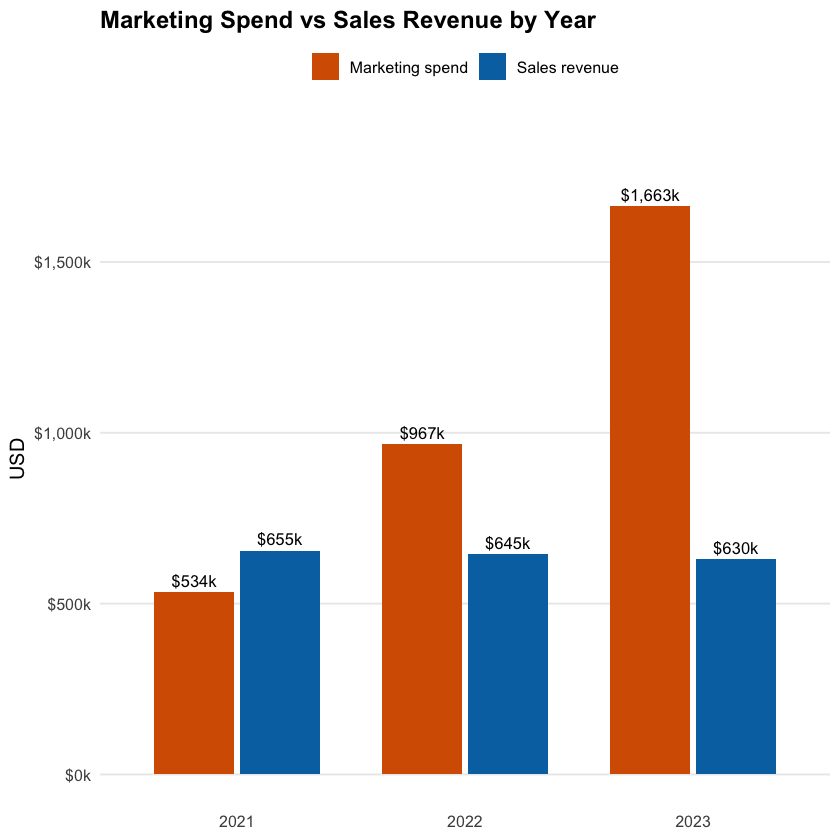

In [35]:
plot_year <- df_year_summary_long |>
    ggplot(aes(x = factor(year), y = usd, fill = measure)) +
    geom_col(position = position_dodge(width = 0.75), width = 0.7) +
    geom_text(
        aes(label = dollar(usd, scale = 1e-3, suffix = "k", accuracy = 1)),
        position = position_dodge(width = 0.75),
        vjust    = -0.5,
        size     = 3.5
    ) +
    scale_y_continuous(labels = dollar_format(scale = 1e-3, suffix = "k")) +
    coord_cartesian(ylim = c(0, 1.85e6)) +   # leave room above the tallest bar for its label
    scale_fill_manual(
        values = c("Marketing spend" = palette_okabe_ito()[6], "Sales revenue" = palette_okabe_ito()[5]),
        name   = NULL
    ) +
    labs(
        title = "Marketing Spend vs Sales Revenue by Year",
        x     = NULL,
        y     = "USD"
    ) +
    theme_minimal(base_size = 12) +
    theme(
        plot.title         = element_text(face = "bold"),
        legend.position    = "top",
        panel.grid.major.x = element_blank(),
        panel.grid.minor   = element_blank()
    )

plot_year

From this figure, we can observe the trends in marketing spend and sales revenue over the years. The marketing spend has been increasing significantly, which grew from $534k in 2021 to $967k in 2022 and $1.66 million in 2023, about 3.1 times. From the table above, we can see that this is because the number of running campaigns rose from 16 to 34 and then to 50. However, over the same period, sales revenue did not grow: it was $655k, $645k and $630k, a small decline each year. As a result, every dollar of marketing spend was associated with $1.23 of revenue in 2021, $0.67 in 2022 and only $0.38 in 2023. This discrepancy highlights the diminishing returns of marketing spend over these years.

**(b) Sales by Product Category**

Next, we look at which product categories bring in the revenue, first in total and then month by month.

In [36]:
# Revenue and order value by product category (completed purchases only)
df_category_summary <-
    df_purchases |>
    group_by(category_name) |>
    summarise(
        revenue         = sum(revenue_usd),
        n_orders        = n(),
        avg_order_value = mean(revenue_usd)
    ) |>
    ungroup() |>
    mutate(share_revenue = revenue / sum(revenue)) |>
    arrange(desc(revenue))

df_category_summary

category_name,revenue,n_orders,avg_order_value,share_revenue
<chr>,<dbl>,<int>,<dbl>,<dbl>
Electronics,803841.02,3731,215.44921,0.41668268
Home,438899.72,3163,138.76058,0.22751005
Fashion,305156.88,3429,88.99297,0.15818250
Sports,229947.61,1807,127.25380,0.11919669
Beauty,83663.93,1592,52.55272,0.04336841
Grocery,67635.17,2514,26.90341,0.03505967


In [37]:
# Monthly revenue of each product category (completed purchases only)
df_category_month <-
    df_purchases |>
    mutate(month = floor_date(purchase_date, "month")) |>   # first day of the month of each purchase
    group_by(category_name, month) |>
    summarise(revenue = sum(revenue_usd), .groups = "drop") |>
    # order the categories from the largest to the smallest, which also orders the legend
    mutate(category_name = factor(category_name, levels = df_category_summary$category_name))

df_category_month |> arrange(month, category_name) |> slice_head(n = 10)

category_name,month,revenue
<fct>,<date>,<dbl>
Electronics,2021-01-01,25543.45
Home,2021-01-01,14221.14
Fashion,2021-01-01,9399.69
Sports,2021-01-01,6400.13
Beauty,2021-01-01,2324.98
Grocery,2021-01-01,1783.37
Electronics,2021-02-01,18056.18
Home,2021-02-01,12548.47
Fashion,2021-02-01,8430.52


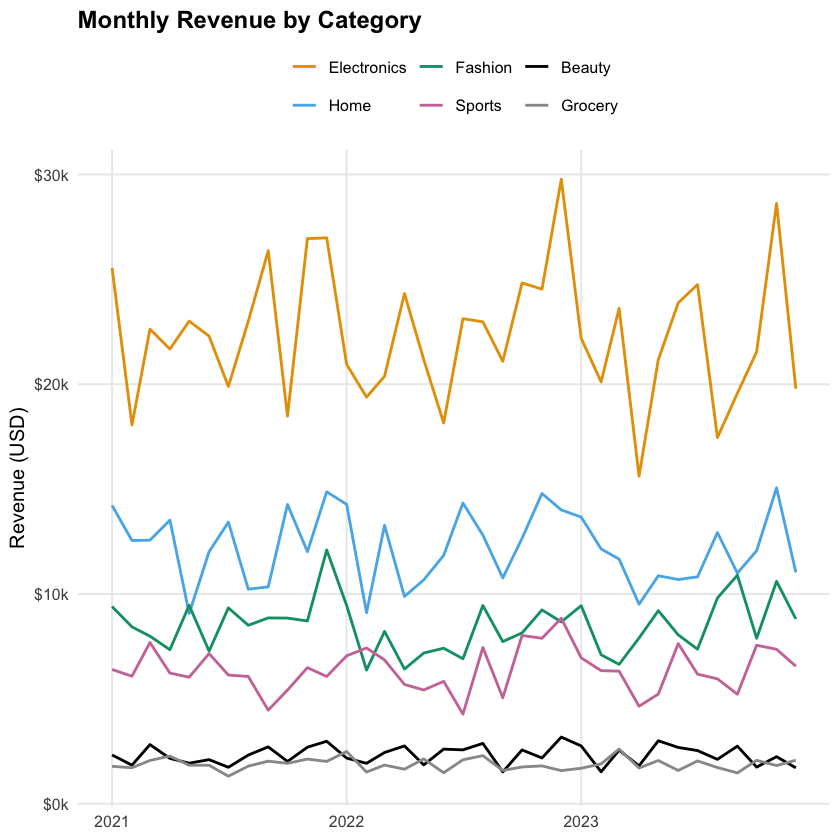

In [38]:
plot_category <- df_category_month |>
    ggplot(aes(x = month, y = revenue, colour = category_name)) +
    geom_line(linewidth = 0.8) +
    scale_x_date(breaks = as.Date(c("2021-01-01", "2022-01-01", "2023-01-01")), date_labels = "%Y") +
    scale_y_continuous(labels = dollar_format(scale = 1e-3, suffix = "k")) +
    scale_color_manual(values = palette_okabe_ito()[c(1, 2, 3, 7, 9, 8)], name = NULL) +
    labs(
        title = "Monthly Revenue by Category",
        x     = NULL,
        y     = "Revenue (USD)"
    ) +
    theme_minimal(base_size = 12) +
    theme(
        plot.title       = element_text(face = "bold"),
        legend.position  = "top",
        panel.grid.minor = element_blank()
    )

plot_category

Electronics is by far the largest category, contributing $804k, or 42% of revenue, followed by Home (23%) and Fashion (16%). Beauty and Grocery are small revenue categories, consistent with their low prices: the average order value is $53 for Beauty and $27 for Grocery, against $215 for Electronics. The monthly lines show that no category is growing. Each one fluctuates around its own level from 2021 to 2023 (Electronics, for example, between about $16k and $30k a month) without a rise or a fall over the three years. This matches the flat total revenue in the yearly comparison above.

**(c) Sales by Country**

Finally, we look at where the revenue comes from geographically. We add each customer's country to the completed purchases, compare each country's share of revenue with its share of customers, and compare the value of the individual transactions.

In [39]:
# Add the country of each customer to the completed purchases, then summarise revenue by country
df_country_summary <-
    df_purchases |>
    left_join(df_customer_full_clean |> select(cust_id, cntry), by = join_by(cust_id)) |>
    group_by(cntry) |>
    summarise(
        revenue            = sum(revenue_usd),
        avg_order_value    = mean(revenue_usd),
        median_order_value = median(revenue_usd),
        share_over_300     = mean(revenue_usd > 300)   # share of transactions worth more than $300
    ) |>
    ungroup() |>
    # Number of customers in each country, including customers who have not bought yet
    left_join(
        df_customer_full_clean |> count(cntry, name = "n_customers"),
        by = join_by(cntry)
    ) |>
    mutate(
        revenue_per_customer = revenue / n_customers,
        share_revenue        = revenue / sum(revenue),
        share_customers      = n_customers / sum(n_customers)
    ) |>
    arrange(desc(revenue))

df_country_summary

cntry,revenue,avg_order_value,median_order_value,share_over_300,n_customers,revenue_per_customer,share_revenue,share_customers
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
US,679813.1,119.3073,85.160,0.07493857,3509,193.7341,0.35239098,0.3509
IN,396315.9,120.4608,83.440,0.08237082,2024,195.8082,0.20543609,0.2024
UK,203158.4,117.9782,82.830,0.06620209,1042,194.9697,0.10531011,0.1042
BR,185881.3,113.9677,81.000,0.06437768,1010,184.0409,0.09635428,0.1010
CA,181984.7,118.7115,82.290,0.06457926,958,189.9631,0.09433441,0.0958
DE,153128.7,118.8888,84.175,0.07531056,789,194.0795,0.07937651,0.0789
AU,128862.2,119.9835,83.450,0.06517691,668,192.9075,0.06679761,0.0668


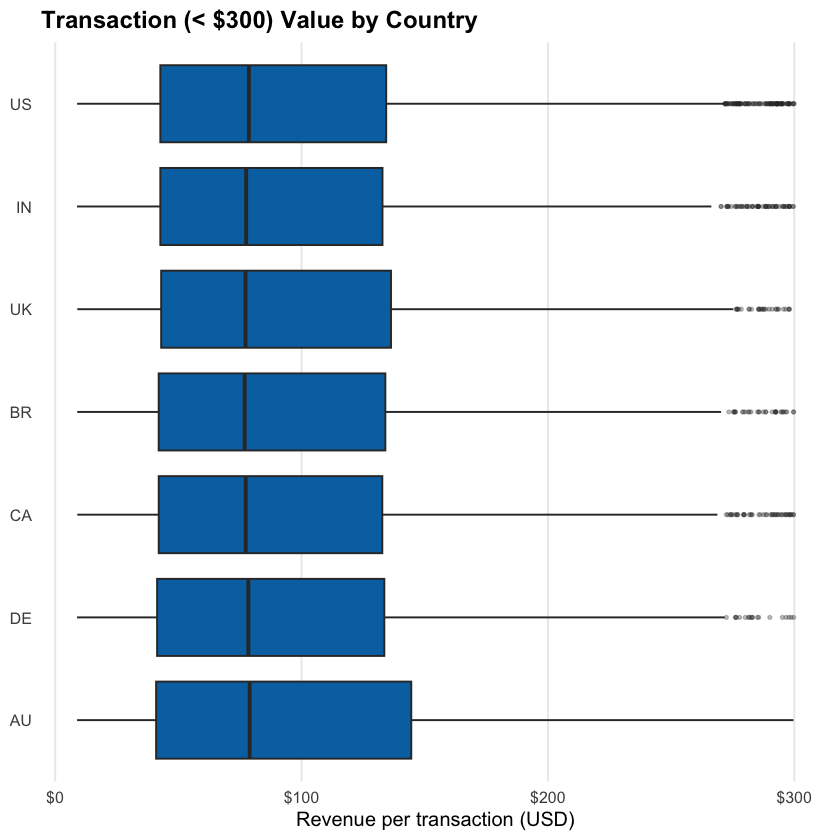

In [40]:
# Distribution of the value of each transaction, by country (completed purchases only,
# without the extreme transactions: the lowest 1% and everything above $300)
plot_country <-
    df_purchases |>
    left_join(df_customer_full_clean |> select(cust_id, cntry), by = join_by(cust_id)) |>
    filter(
        revenue_usd >= quantile(revenue_usd, 0.01),
        revenue_usd <= 300
    ) |>
    mutate(cntry = factor(cntry, levels = rev(df_country_summary$cntry))) |>   # largest market at the top
    ggplot(aes(x = revenue_usd, y = cntry)) +
    geom_boxplot(
        fill          = palette_okabe_ito()[5],
        outlier.size  = 0.8,
        outlier.alpha = 0.3
    ) +
    scale_x_continuous(labels = dollar_format()) +
    labs(
        title = "Transaction (< $300) Value by Country",
        x     = "Revenue per transaction (USD)",
        y     = NULL
    ) +
    theme_minimal(base_size = 12) +
    theme(
        plot.title         = element_text(face = "bold"),
        panel.grid.major.y = element_blank(),
        panel.grid.minor   = element_blank()
    )

plot_country

The summary table shows that the United States (35% of revenue) and India (21%) are the largest markets, followed by the UK, Brazil and Canada (about 10% each), while Germany (8%) and Australia (7%) are the smallest; in every country, the share of revenue is almost the same as the share of customers. The boxplot shows that the transaction values are also distributed similarly in all countries, with a median of about $75. The only exception is Australia, whose box is slightly longer, which suggests somewhat more high-value transactions there.

#### (2) Rule-Based Segmentation: RFM

We now turn to rule-based segmentation (RFM) of customers analyzing their Recency, Frequency, and Monetary value.

**(a) RFM Data Preparation**

We first prepare the data for the RFM method from class. RFM scores are defined for buyers only, so we keep the buyers from the customer full table. Each of the three measures is converted into quintile scores from 1 to 5 with `ntile()`, and the recency score is reversed so that 5 always means "better" (more recent, more frequent, higher spend). Before using the scores, we check what the frequency quintiles actually contain.

In [41]:
df_rfm_data <-
    df_customer_full_clean |>
    filter(buyer == "Buyer") |>   # RFM scores are defined for buyers only
    select(cust_id, recency, frequency, monetary) |>
    mutate(
        r_tile = ntile(recency, 5),
        f_tile = ntile(frequency, 5),
        m_tile = ntile(monetary, 5)
    ) |>
    mutate(
        # Reverse R so that R = 5 means the most recent buyers, in line with F and M
        r_tile = max(r_tile) - r_tile + 1
    )

df_rfm_data |> slice_head(n = 10)

cust_id,recency,frequency,monetary,r_tile,f_tile,m_tile
<dbl>,<dbl>,<int>,<dbl>,<dbl>,<int>,<int>
1,11,1,88.80,3,1,2
26,20,1,54.35,2,1,1
27,8,1,81.30,4,1,2
32,23,1,100.17,1,1,2
49,34,1,39.19,1,1,1
57,14,2,201.34,3,3,3
77,7,3,367.31,4,4,4
103,7,2,43.92,4,3,1
129,21,1,27.04,2,1,1


**(b) RFM Segments**

We now map score combinations to the ten standard segment names.

In [42]:
df_rfm_segmented <-
    df_rfm_data |>
    mutate(
        rfm_segment = case_when(
            r_tile == 5 & f_tile == 5 & m_tile == 5             ~ "Champions",
            r_tile %in% 3:5 & f_tile %in% 3:5 & m_tile %in% 2:5 ~ "Potential Loyalist",
            r_tile %in% 2:4 & f_tile %in% 2:4 & m_tile %in% 2:4 ~ "Loyal Customers",
            r_tile %in% 3:4 & f_tile %in% 1:3 & m_tile %in% 3:5 ~ "Promising",
            r_tile %in% 4:5 & f_tile %in% 1:3 & m_tile %in% 1:5 ~ "New Customers",
            r_tile %in% 1:2 & f_tile %in% 3:4 & m_tile %in% 4:5 ~ "Can't Lose Them",
            r_tile %in% 1:2 & f_tile %in% 2:5 & m_tile %in% 4:5 ~ "At Risk",
            r_tile %in% 1:3 & f_tile %in% 3:5 & m_tile %in% 3:5 ~ "Need Attention",
            r_tile %in% 2:3 & f_tile %in% 1:3 & m_tile %in% 1:4 ~ "About To Sleep",
            r_tile == 1                                         ~ "Lost",
            .default = "Unclassified"
        )
    )

df_rfm_segmented |> slice_head(n = 10)

cust_id,recency,frequency,monetary,r_tile,f_tile,m_tile,rfm_segment
<dbl>,<dbl>,<int>,<dbl>,<dbl>,<int>,<int>,<chr>
1,11,1,88.80,3,1,2,About To Sleep
26,20,1,54.35,2,1,1,About To Sleep
27,8,1,81.30,4,1,2,New Customers
32,23,1,100.17,1,1,2,Lost
49,34,1,39.19,1,1,1,Lost
57,14,2,201.34,3,3,3,Potential Loyalist
77,7,3,367.31,4,4,4,Potential Loyalist
103,7,2,43.92,4,3,1,New Customers
129,21,1,27.04,2,1,1,About To Sleep


Then, we summarize the RFM segments to understand the distribution of customers and their contribution to revenue.

In [43]:
df_rfm_summary_wide <- df_rfm_segmented |>
    group_by(rfm_segment) |>
    summarise(
        n_customers   = n(),
        avg_recency   = mean(recency),
        avg_frequency = mean(frequency),
        avg_monetary  = mean(monetary),
        revenue       = sum(monetary)
    ) |>
    ungroup() |>
    mutate(
        customer_share = n_customers / sum(n_customers),
        revenue_share  = revenue / sum(revenue)
    ) |>
    arrange(desc(revenue_share))

df_rfm_summary_wide

rfm_segment,n_customers,avg_recency,avg_frequency,avg_monetary,revenue,customer_share,revenue_share
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Potential Loyalist,2871,6.067921,2.910832,345.29128,991331.27,0.376425856,0.51387097
Champions,344,1.119186,4.767442,702.41073,241629.29,0.045102924,0.12525205
Loyal Customers,956,15.413180,1.618201,183.25674,175193.44,0.125344172,0.09081407
Lost,1179,28.787108,1.083121,99.57868,117403.26,0.154582405,0.06085769
At Risk,252,21.190476,2.900794,456.61135,115066.06,0.033040514,0.05964616
Can't Lose Them,234,22.717949,2.247863,474.39111,111007.52,0.030680477,0.05754236
About To Sleep,827,15.235792,1.043531,66.68422,55147.85,0.108430576,0.02858669
New Customers,628,3.135350,1.095541,86.02253,54022.15,0.082339059,0.02800317
Promising,125,9.360000,1.000000,269.08192,33635.24,0.016389144,0.01743532


Then, we plot the distribution of customers and their contribution to revenue across different RFM segments.

In [44]:
df_rfm_summary_long <- df_rfm_summary_wide |>
    select(rfm_segment, customer_share, revenue_share) |>
    arrange(customer_share) |>   # smallest first, so that the largest segment is at the top of the chart
    mutate(
        # Axis label: the segment name followed by its share of buyers, e.g. "Champions (5%)"
        rfm_label = paste0(rfm_segment, " (", percent(customer_share, accuracy = 1), ")")
    ) |>
    pivot_longer(
        cols      = c(customer_share, revenue_share),
        names_to  = "measure",
        values_to = "share"
    ) |>
    mutate(
        measure   = if_else(measure == "customer_share", "Share of buyers", "Share of revenue"),
        rfm_label = factor(rfm_label, levels = unique(rfm_label))
    )

df_rfm_summary_long |> slice_head(n = 6)

rfm_segment,rfm_label,measure,share
<chr>,<fct>,<chr>,<dbl>
Unclassified,Unclassified (1%),Share of buyers,0.008915694
Unclassified,Unclassified (1%),Share of revenue,0.004355330
Promising,Promising (2%),Share of buyers,0.016389144
Promising,Promising (2%),Share of revenue,0.017435315
Need Attention,Need Attention (2%),Share of buyers,0.018749181
Need Attention,Need Attention (2%),Share of revenue,0.013636196


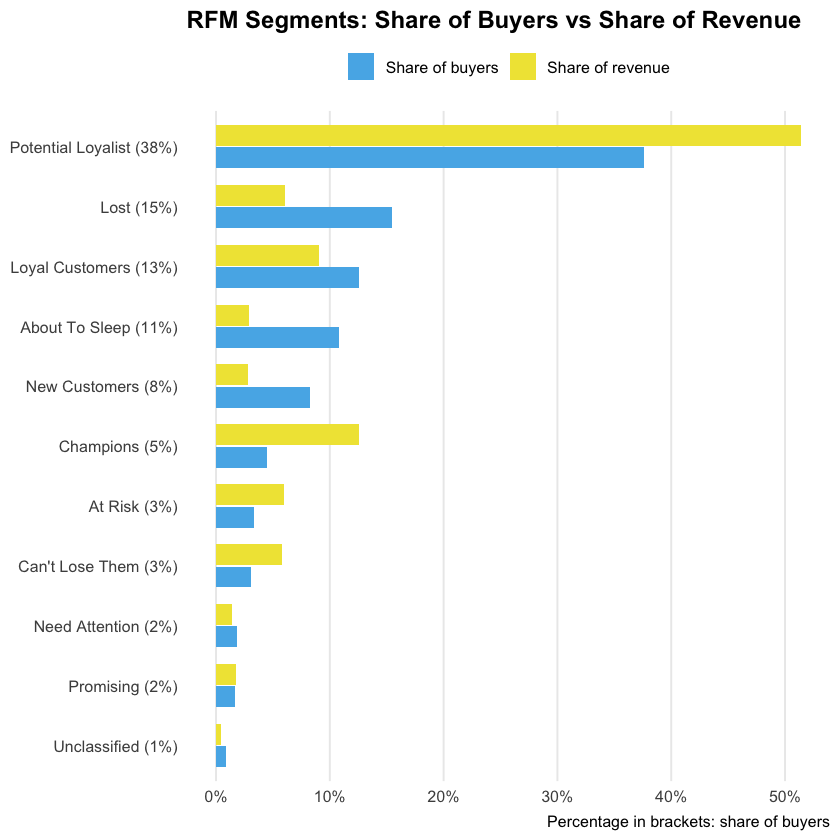

In [45]:
# Compare each segment's share of customers with its share of revenue
plot_rfm <-
    df_rfm_summary_long |>
    ggplot(aes(x = share, y = rfm_label, fill = measure)) +
    geom_col(position = position_dodge(width = 0.75), width = 0.7) +
    scale_x_continuous(labels = percent_format(accuracy = 1)) +
    scale_fill_manual(
        values = c("Share of buyers" = palette_okabe_ito()[2], "Share of revenue" = palette_okabe_ito()[4]),
        name   = NULL
    ) +
    labs(
        title   = "RFM Segments: Share of Buyers vs Share of Revenue",
        x       = NULL,
        y       = NULL,
        caption = "Percentage in brackets: share of buyers"
    ) +
    theme_minimal(base_size = 12) +
    theme(
        plot.title         = element_text(face = "bold"),
        legend.position    = "top",
        panel.grid.major.y = element_blank(),
        panel.grid.minor   = element_blank()
    )

plot_rfm

The table and the chart above show clearly that different types of customers are not equally important. Four groups stand out:

- **Potential Loyalists** are the largest segment, with 38% of buyers, and contribute more than half of revenue. On average they bought about six months ago, placed about three orders and spent $345 each.
- **Champions** are only 5% of buyers (344) but generate the second-largest share of revenue. They bought within the last month on average, placed almost five orders and spent $702 each, the highest of all segments.
- **Lost** customers are 15% of buyers but generate only 6% of revenue. They last bought more than two years ago, placed about one order and spent about $100 each.
- **At Risk** and **Can't Lose Them** customers (486 buyers combined) are small groups that spent about $460 each, but have not bought for almost two years.

#### (3) Data-Driven Segmentation: K-Means

We now bring in the event table and use K-means to group customers by **how much they spend and how long they stay on the site**. For every customer we use two features: the total spend and the average session duration. Using only two features has a practical advantage: the clusters can be drawn directly on these two axes, instead of being projected onto abstract principal components. The outcome we want to understand is the **conversion rate**, the share of visits that ended in a purchase. We do not use it to build the clusters; we compare it across the clusters afterwards.

First, we remove the extreme values from the dataset: the spending more than $1,500 and the average session duration longer than 300 seconds. Such values make most customers be concentrated and squeezed into one corner, and they pull the cluster centres towards them. We therefore leave these customers out of the clustering.

In [46]:
df_behaviour_trimmed <-
    df_customer_full_clean |>
    select(cust_id, n_visits, avg_duration, conversion, monetary) |>
    mutate(monetary = coalesce(monetary, 0)) |>   # customers without a completed purchase spent 0
    filter(
        monetary     <= 1500,
        avg_duration <= 300
    )

For K-means clustering, we first standardise the two features with a `recipe()`. The conversion rate is deliberately left out.

In [47]:
df_behaviour_rec <-
    recipe(~ monetary + avg_duration, data = df_behaviour_trimmed) |>
    step_normalize(all_numeric_predictors())

df_behaviour_scaled <-
    df_behaviour_rec |>
    prep() |>
    bake(new_data = NULL)

# Verify: every scaled variable should have mean 0 and standard deviation 1
df_behaviour_scaled |>
    summarise(across(everything(), list(mean = mean, sd = sd))) |>
    round(3)

monetary_mean,monetary_sd,avg_duration_mean,avg_duration_sd
<dbl>,<dbl>,<dbl>,<dbl>
0,1,0,1


Then, we use the elbow method on all customers and the silhouette method on a random sample of 1,000 customers, to choose an appropriate number of clusters.

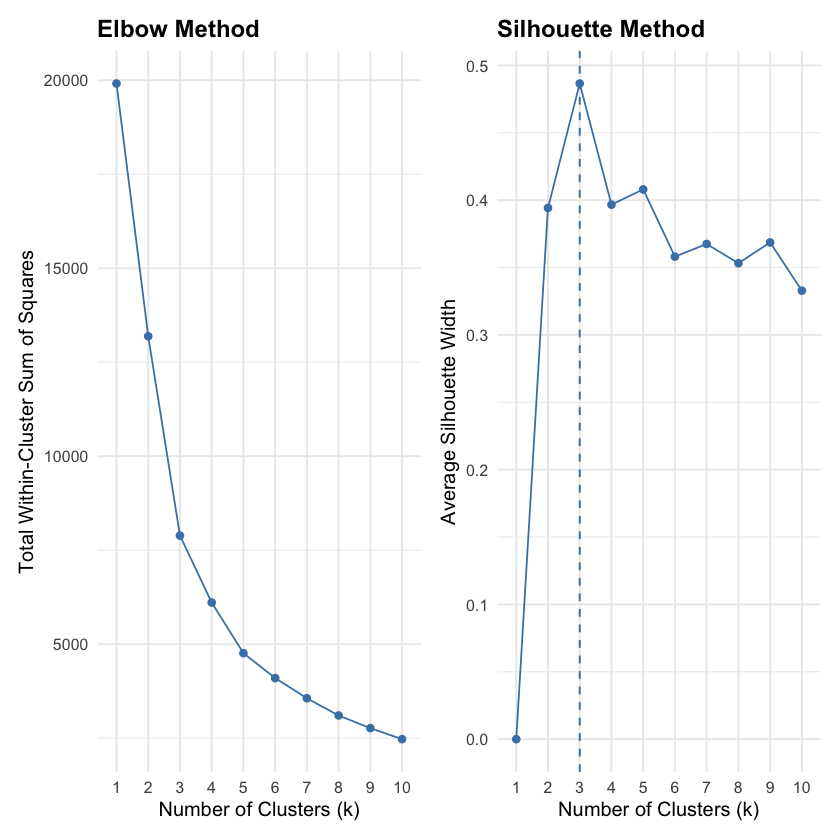

In [48]:
# Elbow method: total within-cluster sum of squares for k = 1 to 10
plot_elbow <-
    fviz_nbclust(df_behaviour_scaled, kmeans, method = "wss", k.max = 10, nstart = 10) +
    labs(
        title = "Elbow Method",
        x     = "Number of Clusters (k)",
        y     = "Total Within-Cluster Sum of Squares"
    ) +
    theme_minimal(base_size = 12) +
    theme(plot.title = element_text(face = "bold"))

# Silhouette method on a random sample of 1,000 customers (as in class, to keep computation fast)
set.seed(42)
df_behaviour_scaled_sample <-
    df_behaviour_scaled |>
    sample_n(1000)

plot_silhouette <-
    fviz_nbclust(df_behaviour_scaled_sample, kmeans, method = "silhouette", k.max = 10) +
    labs(
        title = "Silhouette Method",
        x     = "Number of Clusters (k)",
        y     = "Average Silhouette Width"
    ) +
    theme_minimal(base_size = 12) +
    theme(plot.title = element_text(face = "bold"))

plot_elbow | plot_silhouette

In this elbow method plot, there is no clear single point where the curve bends sharply, but in the silhouette method plot, the average silhouette width peaks at k = 3 (about 0.49) and drops for larger k. We therefore choose **k = 3** for our K-means clustering.

In [49]:
set.seed(123)

# nstart = 25: try 25 random starting points and keep the best solution
kmeans_3 <- kmeans(df_behaviour_scaled, centers = 3, nstart = 25)

# Attach the cluster label to each customer, keeping the original (unstandardised) variables
df_behaviour_clustered <- augment(kmeans_3, df_behaviour_trimmed)

df_behaviour_clustered |> slice_head(n = 5)

cust_id,n_visits,avg_duration,conversion,monetary,.cluster
<dbl>,<int>,<dbl>,<dbl>,<dbl>,<fct>
1,18,189.1000,0.05555556,88.80,1
6,23,119.3609,0.00000000,0.00,3
16,14,107.9214,0.00000000,0.00,3
26,21,101.7238,0.04761905,54.35,3
27,19,119.0158,0.05263158,81.30,3


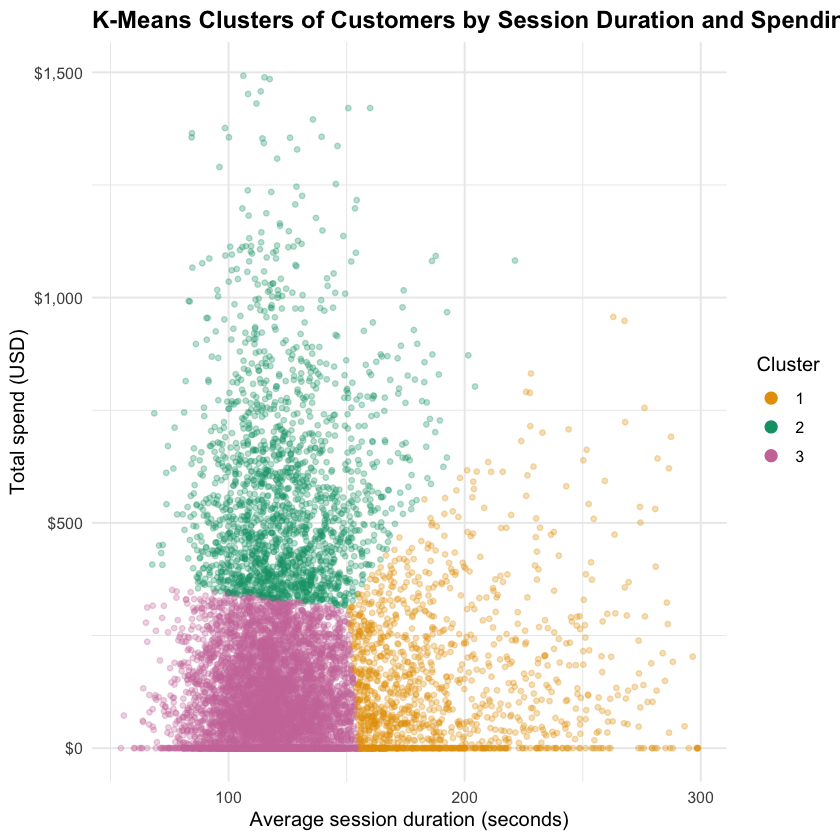

In [50]:
# With only two features, we can plot the clusters directly on the two original axes
plot_kmeans <-
    df_behaviour_clustered |>
    ggplot(aes(x = avg_duration, y = monetary, colour = .cluster)) +
    geom_point(alpha = 0.3, size = 1.2) +
    scale_y_continuous(labels = dollar_format()) +
    scale_color_manual(values = palette_okabe_ito()[c(1, 3, 7)], name = "Cluster") +
    guides(colour = guide_legend(override.aes = list(alpha = 1, size = 3))) +   # solid points in the legend
    labs(
        title = "K-Means Clusters of Customers by Session Duration and Spending (k = 3)",
        x     = "Average session duration (seconds)",
        y     = "Total spend (USD)"
    ) +
    theme_minimal(base_size = 12) +
    theme(plot.title = element_text(face = "bold"))

plot_kmeans

The plot shows every customer on the two original axes. One cluster (green) contains the high spenders, who have ordinary session lengths. A second cluster (orange) forms a band to the right: customers with much longer sessions but low spending. The largest cluster (purple) contains customers with typical sessions and low spending. The row of points along $0 are the customers who never completed a purchase.

To describe the clusters, we summarise them in original units.

In [51]:
# Describe each cluster in original units; the conversion rate is the outcome we compare
df_behaviour_clustered |>
    group_by(.cluster) |>
    summarise(
        n_customers    = n(),
        avg_duration   = mean(avg_duration),
        avg_spend      = mean(monetary),
        share_no_spend = mean(monetary == 0),
        avg_visits     = mean(n_visits),
        avg_conversion = mean(conversion)
    ) |>
    ungroup() |>
    knitr::kable(digits = 3)



|.cluster | n_customers| avg_duration| avg_spend| share_no_spend| avg_visits| avg_conversion|
|:--------|-----------:|------------:|---------:|--------------:|----------:|--------------:|
|1        |        1373|      188.638|   142.858|          0.252|     19.614|          0.079|
|2        |        1882|      123.799|   563.073|          0.000|     21.146|          0.171|
|3        |        6702|      118.119|    96.686|          0.301|     19.489|          0.067|

The three clusters differ clearly. 

- Cluster 1 contains 1,373 customers whose sessions are much longer (189 seconds, against about 120 in the other two clusters) but who spend only $143 on average. 
- Cluster 2 contains 1,882 customers who spend $563 on average and have ordinary sessions (124 seconds). 
- Cluster 3 is the largest, with 6,702 customers who spend $97 on average and also have ordinary sessions; 30% of them spent nothing. 

The number of visits is similar in all three clusters (19 to 21). We name them accordingly and compare their conversion rates.

In [52]:
# Give each cluster a descriptive name, based on the profile table above
# (cluster numbers are fixed by set.seed(123))
df_behaviour_clustered <-
    df_behaviour_clustered |>
    mutate(
        segment = case_when(
            .cluster == 1 ~ "Long Sessions",
            .cluster == 2 ~ "High Spenders",
            .cluster == 3 ~ "Low Spenders"
        )
    )

# Compare the outcome: the average conversion rate of each cluster
df_behaviour_clustered |>
    group_by(segment) |>
    summarise(
        n_customers    = n(),
        avg_conversion = mean(conversion)
    ) |>
    ungroup() |>
    arrange(desc(avg_conversion)) |>
    mutate(avg_conversion = percent(avg_conversion, accuracy = 0.1)) |>
    knitr::kable()



|segment       | n_customers|avg_conversion |
|:-------------|-----------:|:--------------|
|High Spenders |        1882|17.1%          |
|Long Sessions |        1373|7.9%           |
|Low Spenders  |        6702|6.7%           |

The High Spenders convert at 17.1%, about two and a half times the rate of the Low Spenders (6.7%), while the Long Sessions customers convert at 7.9%. The link between spending and conversion is largely by construction: the purchase events in the event table almost coincide with the orders in the transaction table (the two counts have a correlation of 0.97 across customers), so the customers who spend the most are mostly those who buy most often. The more informative result is the role of session duration: the customers who stay longest on the site spend only $143 on average, far less than the High Spenders, who have ordinary session lengths. Staying longer on the site does not go together with spending more.

These are descriptive results: they show how browsing time, spending and conversion go together, but not what causes what.

### 4. Data Analysis Summary

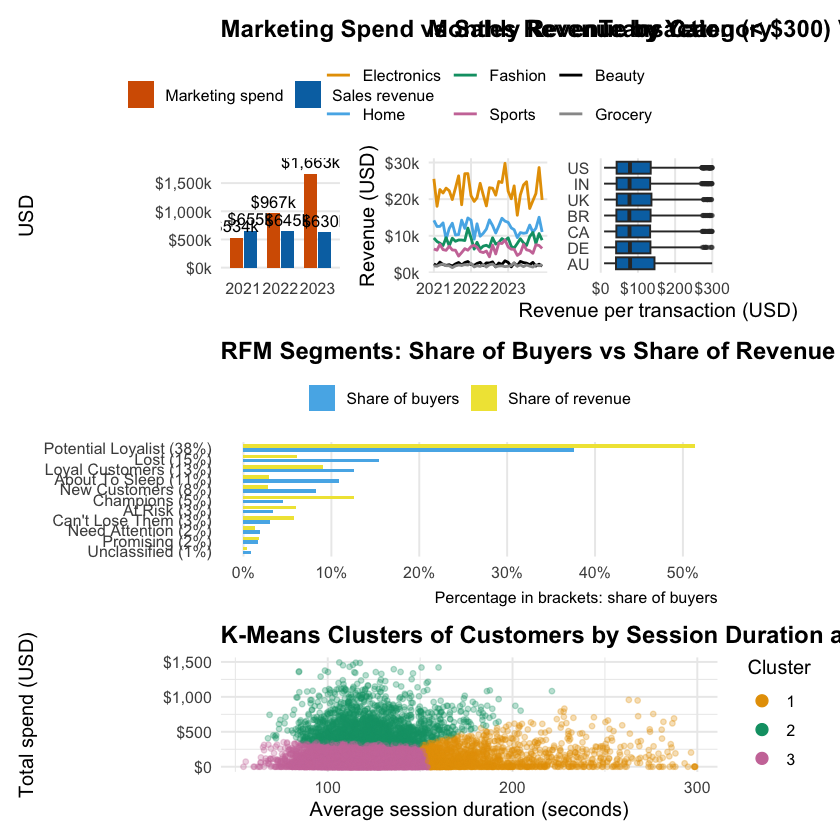

In [53]:
plot_all <-
    (plot_year | plot_category | plot_country) /
    (plot_rfm) /
    (plot_kmeans)

plot_all

## Part B. Analytics Team Memo

### 1. Research Question

- Our research question is: who are Ferdeer Retail's most valuable customers, and how do they differ from the other customers in spending, time on site and conversion?
- The question matters because Ferdeer tripled its marketing spend between 2021 and 2023 while sales revenue stayed flat, so management needs to know which customers deserve the investment.

### 2. Data & Approach

- We cleaned the eight source files into five tables, excluded refunds, and joined them into one table of 10,000 customers with their RFM measures (recency, frequency, monetary value) from 16,236 completed purchases, and their visits, average session duration and conversion rate from 198,094 site visits.
- The analysis is descriptive: we scored buyers on RFM quintiles with `ntile()` and mapped the scores to standard segments, and we ran K-means with k = 3 on two standardised features, total spend and average session duration, after removing extreme customers.
- The conversion rate, the share of a customer's visits that ended in a purchase, is the outcome we compare across clusters, not a feature, and summaries of revenue by year, product category and country give the background.

### 3. Preliminary Findings

- RFM shows that value is concentrated: Potential Loyalists (38% of buyers) generate 51% of revenue, and Champions (5%) generate 13% at $702 per buyer.
- Some valuable customers are slipping away: 486 At Risk or Can't Lose Them buyers spent about $460 each but have not bought for almost two years.
- K-means finds three clusters: the 1,882 High Spenders (19%) spend $563 and convert at 17.1%, against $97 and 6.7% for the 6,702 Low Spenders.
- The 1,373 Long Sessions customers stay 189 seconds per visit, against about 120 for the others, but spend only $143, so time on site does not signal value.
- Where customers live does not distinguish them: US and Indian customers are 55% of customers and generate 56% of revenue, and customers in every country spend $184 to $196 each, whereas what they buy matters more, as customers' Electronics purchases generate 42% of revenue.
- As background, marketing spend grew 3.1 times to $1.66 million while revenue stayed flat, so revenue per dollar of spend fell from $1.23 to $0.38.

### 4. Assumptions & Limitations

- Spending and conversion are linked by construction, because purchase events and orders almost coincide (correlation 0.97), so the High Spenders' high conversion is expected rather than a separate finding.
- The RFM cut-offs from `ntile()` are arbitrary, so segment boundaries are a judgement call, and k = 3 rests on the silhouette width alone, since the elbow curve shows no clear bend.
- We leave customers with spending above $1,500 or sessions above 300 seconds out of the clustering, so the cluster averages understate the largest spenders, and the analysis is descriptive, so the spend and revenue trends do not measure the effect of marketing.

### 5. Open Questions for Feedback

- Should management define high-value customers with the transparent but arbitrary RFM segments, or with the data-driven K-means clusters?
- Did revenue stay flat because extra spend earns diminishing returns, or because the data does not capture the sales that campaigns generate?
- Should refunds reduce a customer's value, rather than being excluded from it?

### 6. Next Steps

- We would track the High Spenders cluster over time to see whether customers move in and out of it.
- We would analyse the checkout experiment to test whether the new checkout designs raise conversion.
- We would compare spend and revenue by channel and campaign to find where the extra spend earned no return.

## Part C. Corporate Brief

### Executive Brief

**Exhibit 1. Customer groups found by the algorithm, by spending and time on site**

In [54]:
#| echo: false
df_behaviour_clustered |>
    group_by(segment) |>
    summarise(
        n_customers = n(),
        avg_spend   = mean(monetary),
        avg_session = mean(avg_duration),
        conversion  = mean(conversion)
    ) |>
    ungroup() |>
    arrange(desc(avg_spend)) |>
    transmute(
        `Customer group`         = segment,
        Customers                = n_customers,
        `Avg. spend (USD)`       = dollar(avg_spend, accuracy = 1),
        `Avg. visit length (seconds)` = round(avg_session),
        `Visits ending in a purchase` = percent(conversion, accuracy = 0.1)
    ) |>
    knitr::kable(align = c("l", rep("r", 4)))



|Customer group | Customers| Avg. spend (USD)| Avg. visit length (seconds)| Visits ending in a purchase|
|:--------------|---------:|----------------:|---------------------------:|---------------------------:|
|High Spenders  |      1882|             $563|                         124|                       17.1%|
|Long Sessions  |      1373|             $143|                         189|                        7.9%|
|Low Spenders   |      6702|              $97|                         118|                        6.7%|

### Executive Summary

We examined who Ferdeer Retail's most valuable customers are, using three years of customer, sales, browsing and campaign data. Ranking customers on how recently, how often and how much they buy (RFM) shows that a small group carries the business: the Champions, only 5% of buyers, generate 13% of revenue. An algorithm that groups customers by spending and time on site finds high spenders who buy in 17% of their visits, against 7% for typical customers, while customers who stay longest on the site do not spend more. Because marketing spend tripled while revenue did not grow, knowing who these customers are should guide next year's budget.

### Key Insights

- RFM shows that value is concentrated: Champions (5% of buyers) generate 13% of revenue and Potential Loyalists (38%) generate 51%, so fewer than half of our buyers bring in almost two thirds of revenue.
- An algorithm that groups customers by spending and time on site finds 1,882 customers who spend $563 each and buy in 17% of their visits, against $97 and 7% for the 6,702 typical customers; those who stay longest on the site spend only $143.
- Where customers live hardly affects what they spend ($184 to $196 each), but what they buy does: Electronics purchases bring in 42% of revenue.

### Business Implications

- A small group of high-spending customers carries the revenue, so keeping them matters more than winning many typical customers.
- Time on site and country do not signal value, so what customers have bought is the better guide for judging them.
- Marketing spend grew from $534k in 2021 to $1.66 million in 2023 while revenue slipped from $655k to $630k, so each dollar now returns $0.38 instead of $1.23 and the added spend is the first place to look for savings.

### Recommended Actions

- Launch a retention programme for the Champions and for the 486 At Risk and Can't Lose Them customers, who spent about $460 each but have not bought for almost two years.
- Choose the audience of each campaign by what customers have bought, such as Electronics, rather than by country or time on site.
- Pause further increases in marketing spend until a review by channel and campaign shows which ones earn a return.

## References

Wickham, H., Averick, M., Bryan, J., Chang, W., McGowan, L. D., François, R., Grolemund, G., Hayes, A., Henry, L., Hester, J., Kuhn, M., Pedersen, T. L., Miller, E., Bache, S. M., Müller, K., Ooms, J., Robinson, D., Seidel, D. P., Spinu, V., ... Yutani, H. (2019). Welcome to the tidyverse. *Journal of Open Source Software, 4*(43), 1686. https://doi.org/10.21105/joss.01686

Kuhn, M., Wickham, H., & Hvitfeldt, E. (2024). *recipes: Preprocessing and feature engineering steps for modeling* (R package). https://recipes.tidymodels.org

Kassambara, A., & Mundt, F. (2020). *factoextra: Extract and visualize the results of multivariate data analyses* (R package version 1.0.7). https://rpkgs.datanovia.com/factoextra/

Firke, S. (2023). *janitor: Simple tools for examining and cleaning dirty data* (R package). https://sfirke.github.io/janitor/

Huntington-Klein, N. (2023). *vtable: Variable summary tables* (R package). https://nickch-k.github.io/vtable/